# Backtest: s14_hrp_setor, s14_hrp_noticias, s14_hrp_placebo, s14_hrp_lw

Gerado por `python -m newsmanager.backtester notebook`. Base das comparações: **s14_hrp_setor**.
Retornos diários líquidos de custo; Sharpe com a taxa livre de risco do TOML (padrão 0).
Pregões em que o arquivo de preços não tem retorno (emendas, deslistagem) contam como 0 para todos.

In [1]:
import sys
from pathlib import Path
ROOT = Path('/Users/gabri/Classes/PapersTCC/NewsManager')
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statistics import NormalDist

from newsmanager import config
from newsmanager.backtester import analysis as A, metrics as M

cfg = config.load(str(ROOT / "config.toml"))
RUNS = ['s14_hrp_setor', 's14_hrp_noticias', 's14_hrp_placebo', 's14_hrp_lw']
BASE = 's14_hrp_setor'
runs = A.load_runs(cfg, RUNS)
first = runs[RUNS[0]]
BENCH = f"benchmark ({first.benchmark_label})" if first.has_benchmark else None
COLORS = dict(zip(RUNS, plt.cm.tab10.colors))
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pct = mtick.PercentFormatter(1.0)
pd.options.display.float_format = "{:.4f}".format

## Configuração das runs

In [2]:
cfg_rows = {}
for n, r in runs.items():
    c = r.config["config"]
    cfg_rows[n] = {"modelo": r.config["model"]["plugin"].split(":")[-1], "params": c["model"]["params"],
                   "período": f"{r.summary['first']} a {r.summary['last']}", "in-sample": c["insample_days"],
                   "rebal.": c["rebalance"], "universo": c["universe"], "peso máx.": c["max_weight"],
                   "peso mín.": c["min_weight"], "custo (bps)": c["cost_bps"], "benchmark": c["benchmark"],
                   "rebalanceamentos": r.summary["rebalances"], "projetados": r.summary["projected_rebalances"],
                   "commit": (r.config.get("git", {}).get("commit") or "")[:8]}
pd.DataFrame(cfg_rows).T

,modelo,params,período,in-sample,rebal.,universo,peso máx.,peso mín.,custo (bps),benchmark,rebalanceamentos,projetados,commit
s14_hrp_setor,HRP,{'cov': 'fator + resíduo setor'},2013-01-02 a 2023-12-28,252,M,{'n': 100},0.1000,0.0000,10,SPY,132,0,a09119aa
s14_hrp_noticias,HRP,{'cov': 'fator + resíduo setor + notícias'},2013-01-02 a 2023-12-28,252,M,{'n': 100},0.1000,0.0000,10,SPY,132,0,a09119aa
s14_hrp_placebo,HRP,"{'cov': 'fator + resíduo setor + notícias', 'c...",2013-01-02 a 2023-12-28,252,M,{'n': 100},0.1000,0.0000,10,SPY,132,0,a09119aa
s14_hrp_lw,HRP,{'cov': 'LW fator único'},2013-01-02 a 2023-12-28,252,M,{'n': 100},0.1000,0.0000,10,SPY,132,0,a09119aa


## Medidas de desempenho (líquidas de custo)

In [3]:
tab = A.metrics_table(runs)
fmt = {k: "{:.2%}" for k in ["cagr", "ann_vol", "max_drawdown", "cvar95_1d", "alpha_ann", "tracking_error", "cost_per_year"]}
tab.style.format(fmt, na_rep="—").format({k: "{:.3f}" for k in tab.columns if k not in fmt}, na_rep="—")

,cagr,ann_vol,sharpe,sortino,max_drawdown,max_dd_days,calmar,skew,excess_kurtosis,cvar95_1d,beta,alpha_ann,tracking_error,information_ratio,turnover_per_year,cost_per_year
s14_hrp_setor,0.117319,0.152154,0.806,1.122,-0.303231,387.000,0.387,-0.607,13.462,0.023131,0.856,0.003634,0.050257,-0.326,3.539,0.003630
s14_hrp_noticias,0.116602,0.152704,0.799,1.111,-0.308832,380.000,0.378,-0.649,14.243,0.023160,0.859,0.002623,0.050029,-0.339,3.721,0.003812
s14_hrp_placebo,0.115819,0.152294,0.796,1.108,-0.299210,382.000,0.387,-0.616,13.131,0.023179,0.857,0.002146,0.049992,-0.354,3.612,0.003703
s14_hrp_lw,0.119730,0.151805,0.821,1.144,-0.299754,357.000,0.399,-0.625,13.487,0.023037,0.853,0.006161,0.050948,-0.280,3.416,0.003507
benchmark (SPY),0.132459,0.170227,0.816,1.140,-0.337173,488.000,0.393,-0.564,13.417,0.026112,—,—,—,—,—,—


## Testes contra a base (s14_hrp_setor)

Razão de variâncias (σ²_run / σ²_base) e diferença de Sharpe, nos pregões em comum, com IC95 e p por
bootstrap circular em blocos de 10 dias (2.000 reamostragens). Para variância mínima, a razão de variâncias
é o teste principal: o objetivo do modelo é a variância, não o retorno.

In [4]:
A.compare(runs, BASE) if len(runs) > 1 else 'só uma run'

,var_ratio,var_ci95,var_p,sharpe_diff,sharpe_ci95,sharpe_p,ann_active_ret,active_vol
s14_hrp_noticias,1.0072,"[0.997, 1.0153]",0.1380,-0.0065,"[-0.0356, 0.0258]",0.6900,-0.0006,0.0080
s14_hrp_placebo,1.0018,"[0.9954, 1.0095]",0.5855,-0.0094,"[-0.0375, 0.0178]",0.5200,-0.0013,0.0070
s14_hrp_lw,0.9954,"[0.9907, 1.0004]",0.0645,0.0157,"[-0.0117, 0.041]",0.2425,0.0021,0.0071


## Patrimônio acumulado (escala log)

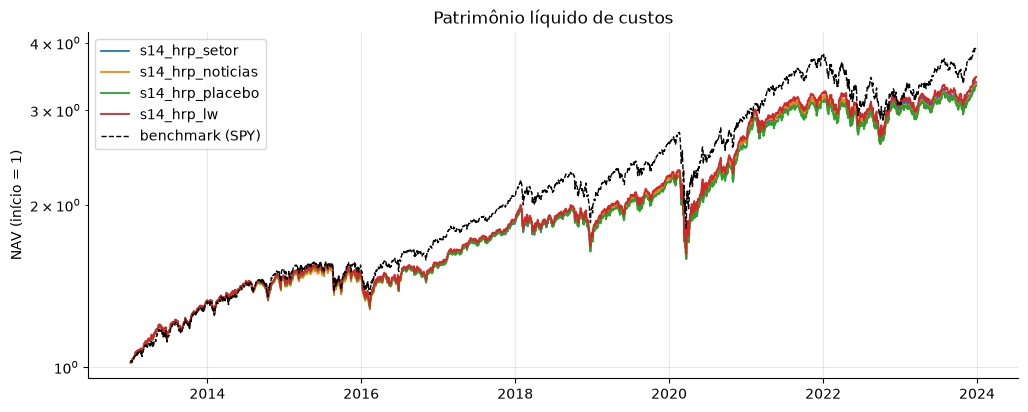

In [5]:
fig, ax = plt.subplots()
for n, r in runs.items():
    ax.plot(r.daily.index, r.daily["nav"], label=n, color=COLORS[n], lw=1.3)
if BENCH:
    ax.plot(first.daily.index, first.daily["bench_nav"], label=BENCH, color="k", lw=1, ls="--")
ax.set_yscale("log"); ax.set_ylabel("NAV (início = 1)"); ax.legend(); ax.set_title("Patrimônio líquido de custos")
plt.show()

## Drawdown

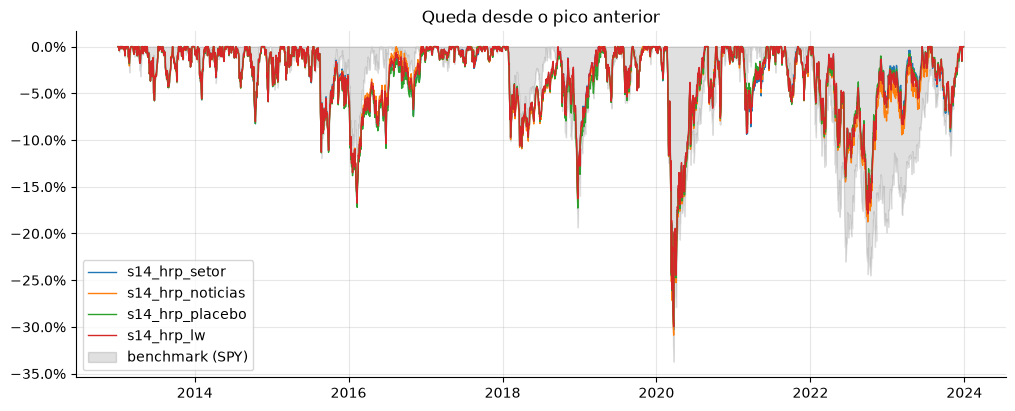

In [6]:
fig, ax = plt.subplots()
for n, r in runs.items():
    ax.plot(r.daily.index, r.daily["drawdown"], label=n, color=COLORS[n], lw=1)
if BENCH:
    ax.fill_between(first.daily.index, first.daily["bench_drawdown"], 0, color="k", alpha=.12, label=BENCH)
ax.yaxis.set_major_formatter(pct); ax.legend(loc="lower left"); ax.set_title("Queda desde o pico anterior")
plt.show()

## Volatilidade, Sharpe e beta móveis (252 pregões)

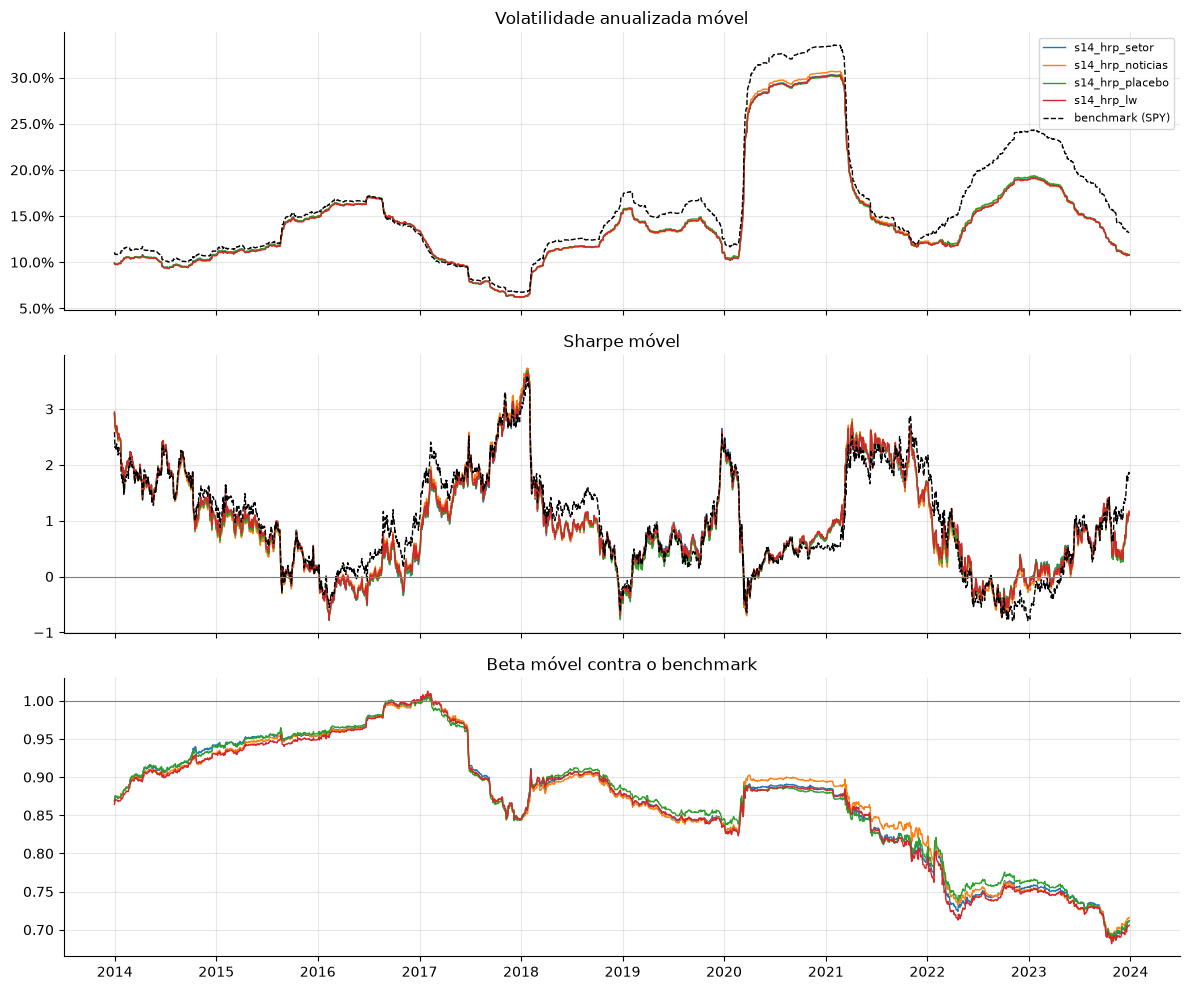

In [7]:
W = 252
fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for n, r in runs.items():
    x = r.daily["ret"]
    axs[0].plot(x.rolling(W).std() * np.sqrt(252), label=n, color=COLORS[n], lw=1)
    axs[1].plot(x.rolling(W).mean() / x.rolling(W).std() * np.sqrt(252), color=COLORS[n], lw=1)
    if r.has_benchmark:
        b = r.daily["bench_ret"]
        axs[2].plot(x.rolling(W).cov(b) / b.rolling(W).var(), color=COLORS[n], lw=1)
if BENCH:
    b = first.daily["bench_ret"]
    axs[0].plot(b.rolling(W).std() * np.sqrt(252), label=BENCH, color="k", ls="--", lw=1)
    axs[1].plot(b.rolling(W).mean() / b.rolling(W).std() * np.sqrt(252), color="k", ls="--", lw=1)
axs[0].yaxis.set_major_formatter(pct); axs[0].set_title("Volatilidade anualizada móvel"); axs[0].legend(fontsize=8)
axs[1].set_title("Sharpe móvel"); axs[1].axhline(0, color="grey", lw=.8)
axs[2].set_title("Beta móvel contra o benchmark"); axs[2].axhline(1, color="grey", lw=.8)
plt.tight_layout(); plt.show()

## Diferença acumulada contra a base

log(NAV_run / NAV_base): sobe quando a run rende mais que a base.

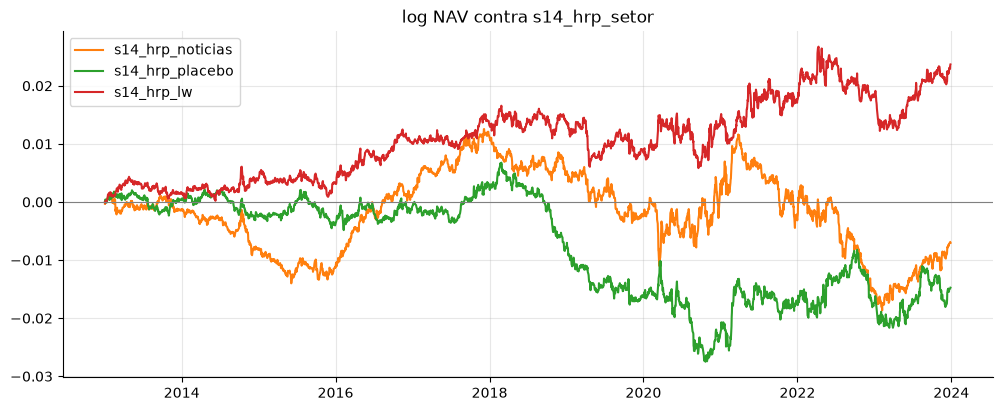

In [8]:
idx = A.common_days(runs)
fig, ax = plt.subplots()
lb = np.log1p(runs[BASE].daily.loc[idx, "ret"]).cumsum()
for n, r in runs.items():
    if n != BASE:
        ax.plot(idx, np.log1p(r.daily.loc[idx, "ret"]).cumsum() - lb, label=n, color=COLORS[n])
ax.axhline(0, color="grey", lw=.8); ax.legend(); ax.set_title(f"log NAV contra {BASE}")
plt.show()

## Retornos mensais

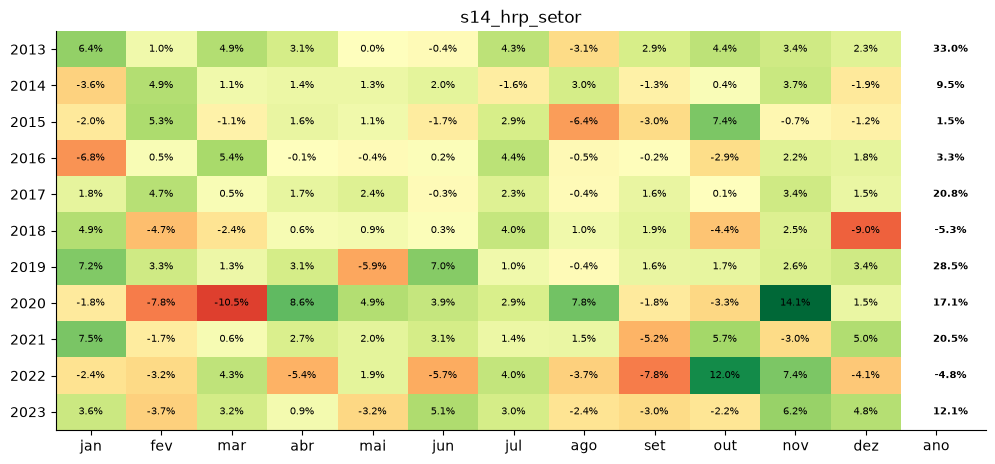

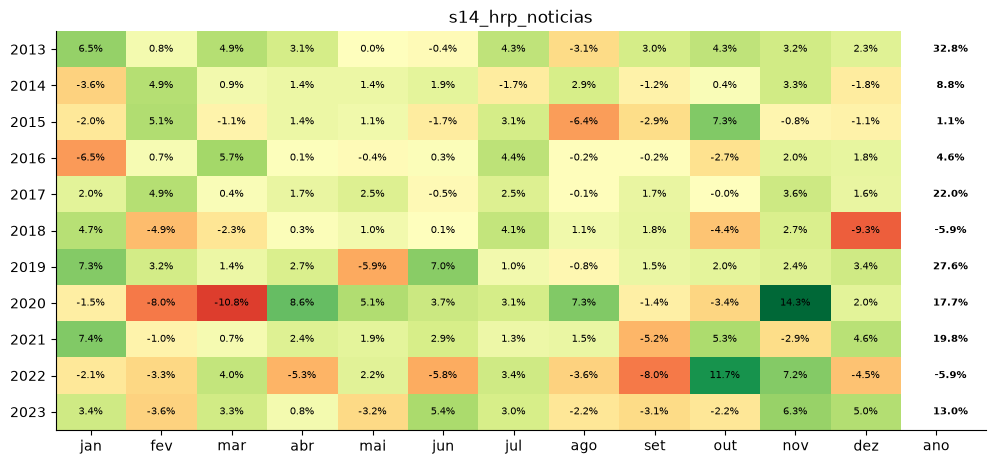

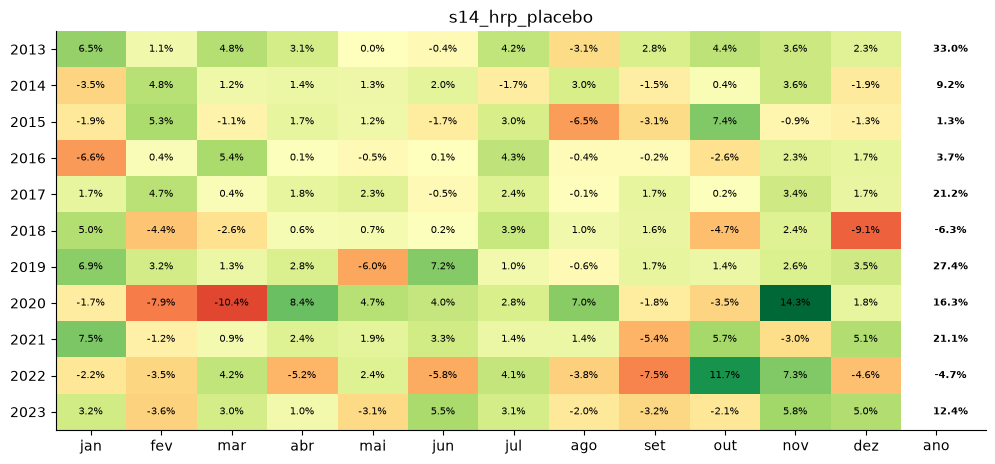

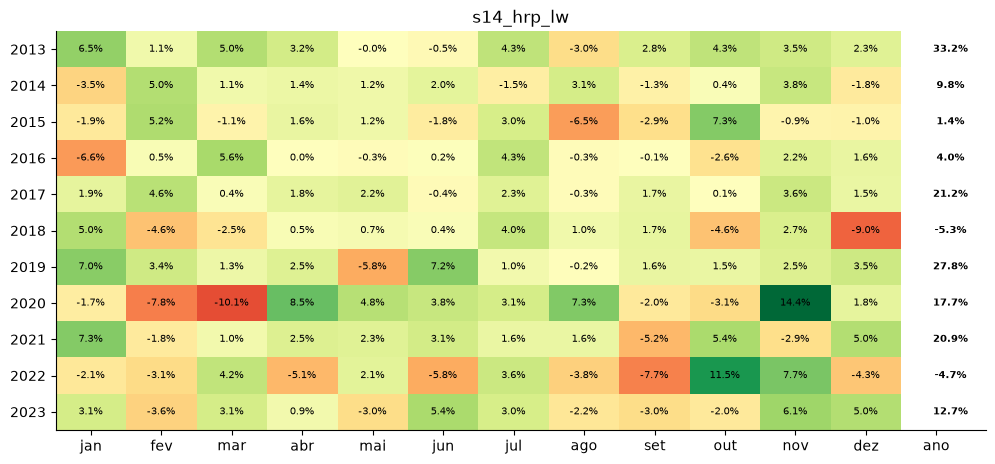

In [9]:
for n, r in runs.items():
    m = (1 + r.daily["ret"]).resample("ME").prod() - 1
    tbl = m.groupby([m.index.year, m.index.month]).first().unstack()
    tbl["ano"] = (1 + tbl.fillna(0)).prod(axis=1) - 1
    fig, ax = plt.subplots(figsize=(12, 0.38 * len(tbl) + 1))
    v = np.nanmax(np.abs(tbl.iloc[:, :12].to_numpy()))
    ax.imshow(tbl.iloc[:, :12], cmap="RdYlGn", vmin=-v, vmax=v, aspect="auto")
    for (i, j), val in np.ndenumerate(tbl.to_numpy()):
        if np.isfinite(val):
            ax.text(j if j < 12 else 12.2, i, f"{val:.1%}", ha="center", va="center", fontsize=7,
                    fontweight="bold" if j == 12 else None)
    ax.set_xticks(range(13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez", "ano"])
    ax.set_yticks(range(len(tbl)), tbl.index); ax.grid(False); ax.set_xlim(-.5, 12.7); ax.set_title(n)
    plt.show()

## Retorno por ano

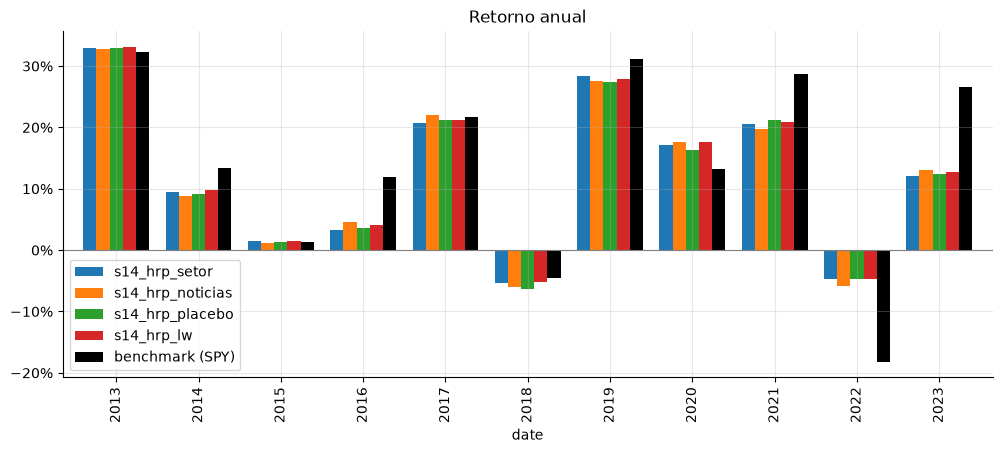

,s14_hrp_setor,s14_hrp_noticias,s14_hrp_placebo,s14_hrp_lw,benchmark (SPY)
date,,,,,
2013,32.95%,32.76%,33.00%,33.16%,32.31%
2014,9.53%,8.82%,9.22%,9.81%,13.46%
2015,1.49%,1.15%,1.35%,1.41%,1.29%
2016,3.33%,4.63%,3.65%,4.04%,12.00%
2017,20.77%,22.04%,21.21%,21.20%,21.71%
2018,-5.30%,-5.95%,-6.29%,-5.27%,-4.57%
2019,28.46%,27.57%,27.35%,27.82%,31.22%
2020,17.06%,17.70%,16.32%,17.68%,13.28%
2021,20.54%,19.78%,21.14%,20.94%,28.73%


In [10]:
ann = pd.DataFrame({n: (1 + r.daily["ret"]).groupby(r.daily.index.year).prod() - 1 for n, r in runs.items()})
if BENCH:
    ann[BENCH] = (1 + first.daily["bench_ret"]).groupby(first.daily.index.year).prod() - 1
ax = ann.plot.bar(figsize=(12, 4.5), color=[COLORS.get(c, "k") for c in ann.columns], width=.8)
ax.yaxis.set_major_formatter(pct); ax.set_title("Retorno anual"); ax.axhline(0, color="grey", lw=.8)
plt.show()
ann.style.format("{:.2%}")

## Distribuição dos retornos diários

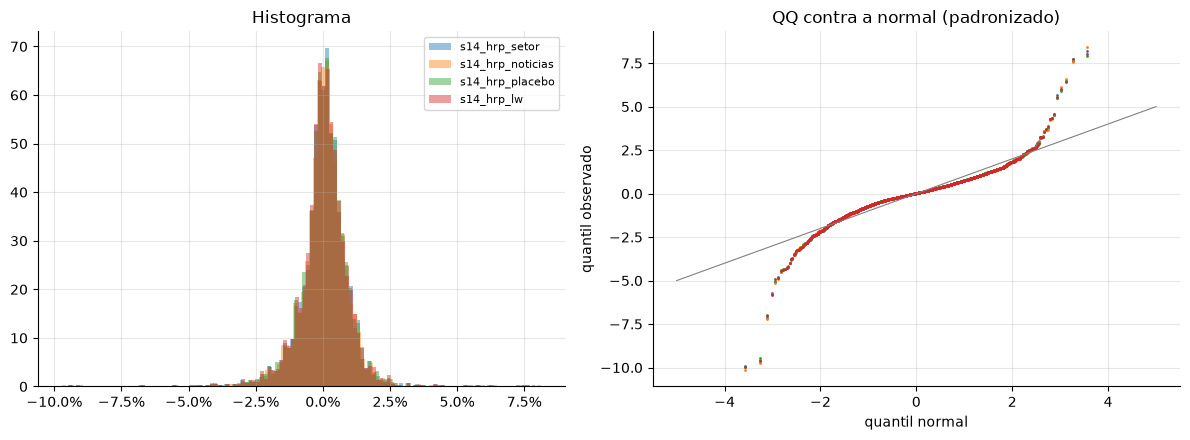

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for n, r in runs.items():
    x = r.daily["ret"].to_numpy()
    axs[0].hist(x, bins=120, alpha=.45, density=True, label=n, color=COLORS[n])
    q = np.sort((x - x.mean()) / x.std())
    t = [NormalDist().inv_cdf((i + .5) / len(q)) for i in range(len(q))]
    axs[1].plot(t, q, ".", ms=2, color=COLORS[n], label=n)
axs[0].xaxis.set_major_formatter(pct); axs[0].set_title("Histograma"); axs[0].legend(fontsize=8)
axs[1].plot([-5, 5], [-5, 5], color="grey", lw=.8); axs[1].set_title("QQ contra a normal (padronizado)")
axs[1].set_xlabel("quantil normal"); axs[1].set_ylabel("quantil observado")
plt.tight_layout(); plt.show()

## Giro e custos

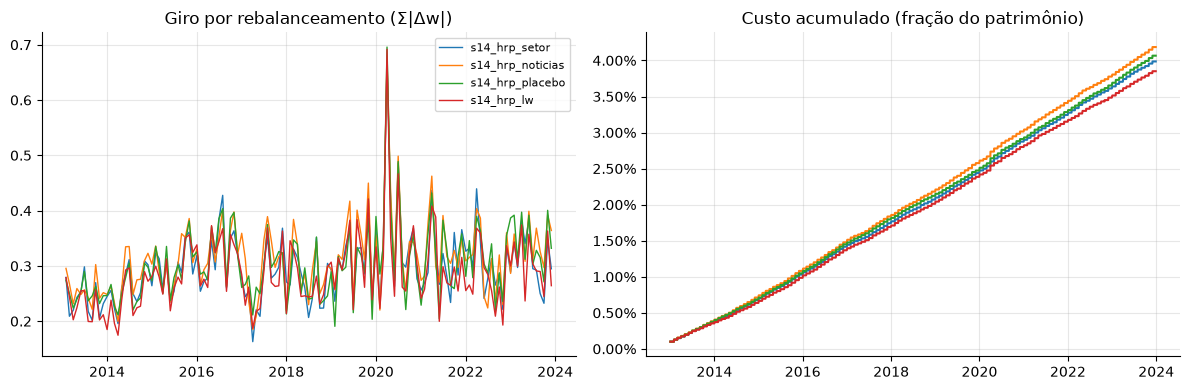

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for n, r in runs.items():
    rb = r.rebalances.iloc[1:]   # o primeiro monta a carteira inteira
    axs[0].plot(rb.index, rb["turnover"], label=n, color=COLORS[n], lw=1)
    axs[1].plot(r.daily.index, r.daily["cost"].cumsum(), label=n, color=COLORS[n])
axs[0].set_title("Giro por rebalanceamento (Σ|Δw|)"); axs[0].legend(fontsize=8)
axs[1].yaxis.set_major_formatter(pct); axs[1].set_title("Custo acumulado (fração do patrimônio)")
plt.tight_layout(); plt.show()

## Concentração

Número efetivo de ativos 1/Σw², maior peso e número de posições, a cada rebalanceamento.

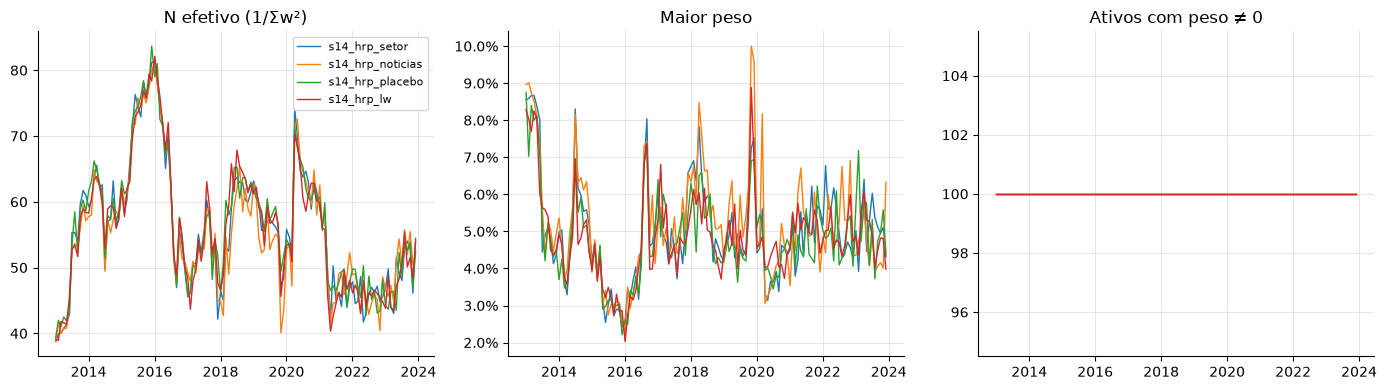

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for n, r in runs.items():
    rb = r.rebalances
    axs[0].plot(rb.index, rb["eff_n"], color=COLORS[n], label=n, lw=1)
    axs[1].plot(rb.index, rb["w_max"], color=COLORS[n], lw=1)
    axs[2].plot(rb.index, rb["n_assets"], color=COLORS[n], lw=1)
axs[0].set_title("N efetivo (1/Σw²)"); axs[0].legend(fontsize=8)
axs[1].set_title("Maior peso"); axs[1].yaxis.set_major_formatter(pct)
axs[2].set_title("Ativos com peso ≠ 0")
plt.tight_layout(); plt.show()

## Composição: maiores posições ao longo do tempo

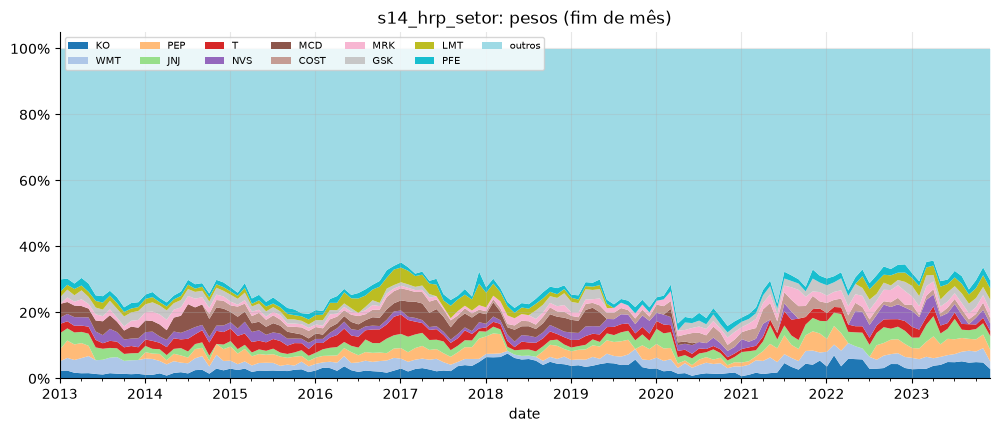

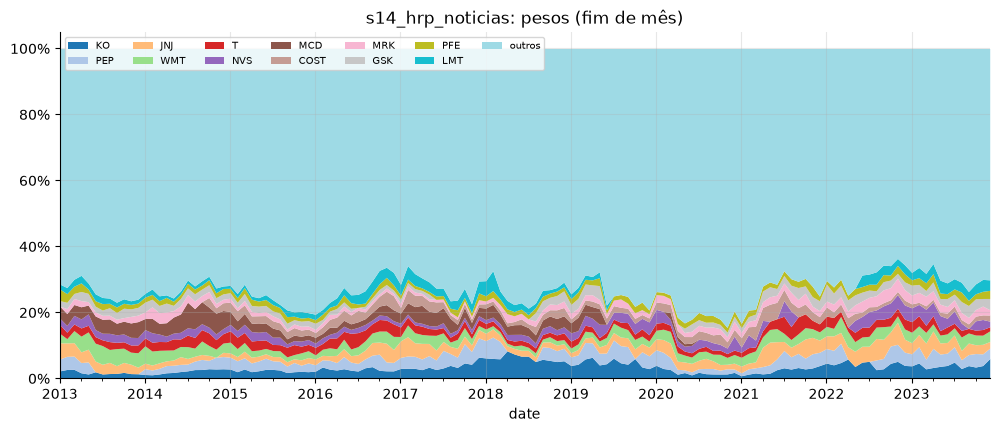

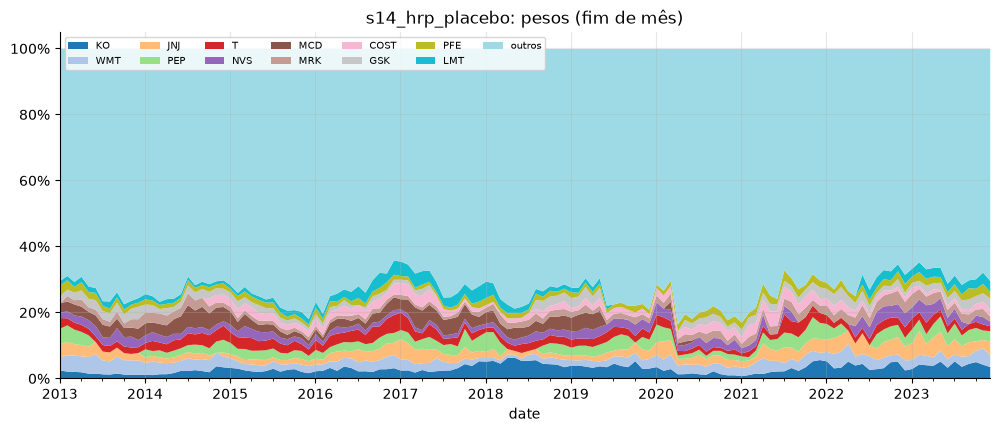

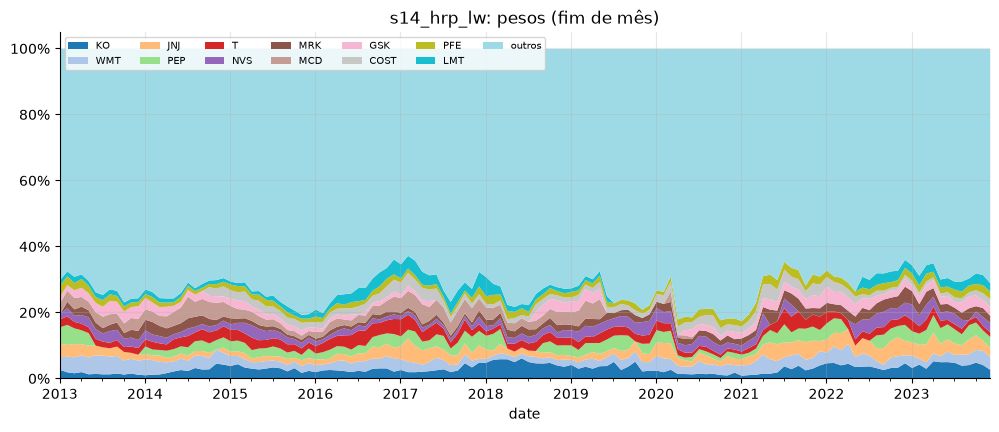

In [14]:
TOP = 12
for n, r in runs.items():
    P = r.positions.pivot_table(index="date", columns="ticker", values="weight", aggfunc="sum").fillna(0)
    P = P.resample("ME").last()
    top = P.mean().nlargest(TOP).index
    S = P[top].copy(); S["outros"] = P.drop(columns=top).sum(axis=1)
    ax = S.plot.area(figsize=(12, 4.5), linewidth=0, cmap="tab20")
    ax.yaxis.set_major_formatter(pct); ax.set_title(f"{n}: pesos (fim de mês)"); ax.legend(ncol=7, fontsize=7, loc="upper left")
    plt.show()

## Alocação por setor (Fama-French 12)

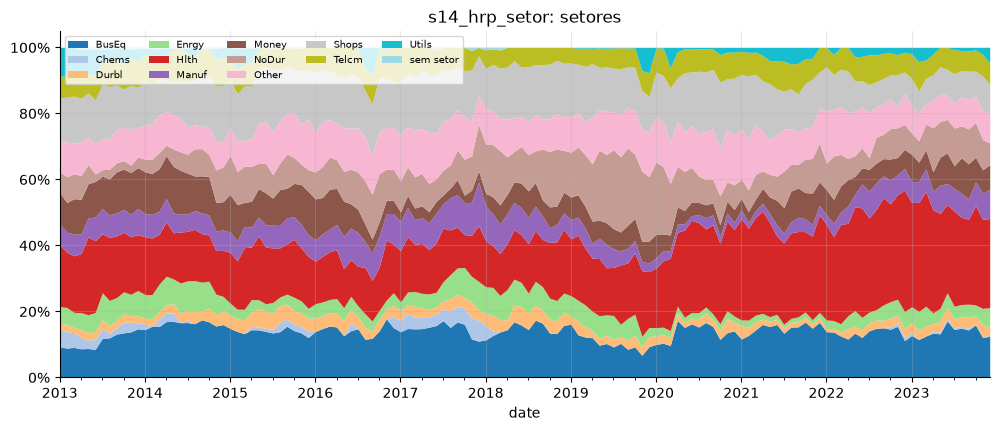

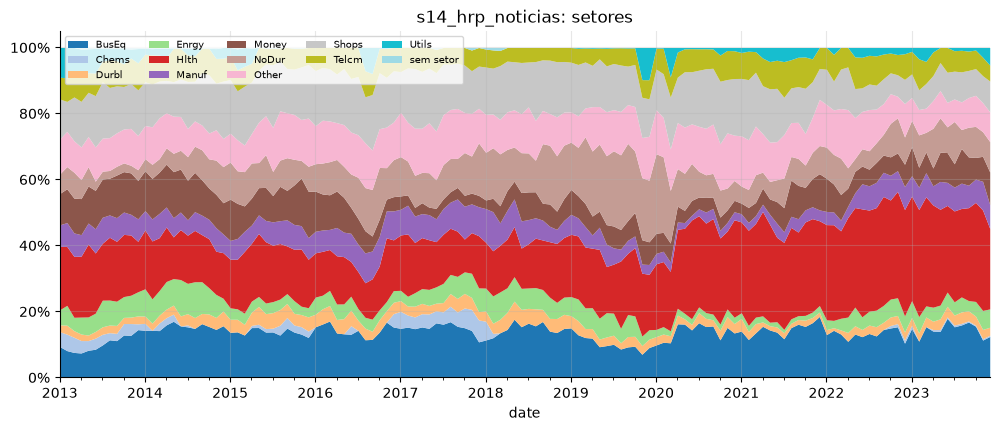

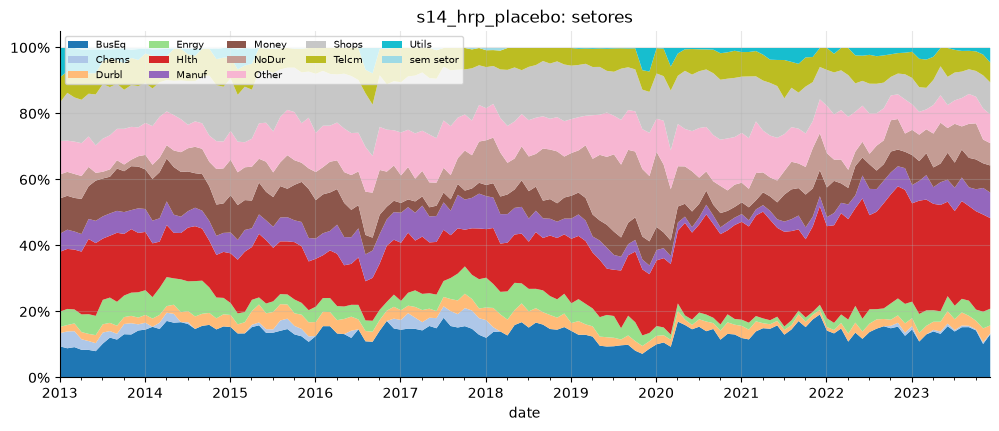

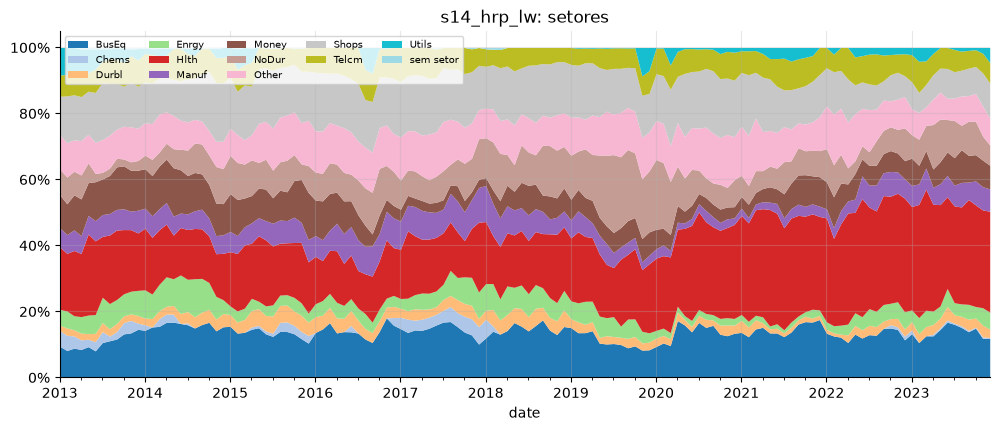

In [15]:
for n, r in runs.items():
    pos = r.positions
    sec = A.sectors(cfg, pos["ticker"].unique().tolist())
    S = (pos.assign(setor=pos["ticker"].map(sec)).groupby(["date", "setor"])["weight"].sum()
            .unstack().fillna(0).resample("ME").last())
    ax = S.plot.area(figsize=(12, 4.5), linewidth=0, cmap="tab20")
    ax.yaxis.set_major_formatter(pct); ax.set_title(f"{n}: setores"); ax.legend(ncol=5, fontsize=7, loc="upper left")
    plt.show()

## Contribuição ao retorno por ativo

Soma de w_início-do-dia × retorno no período (aproximação aritmética).

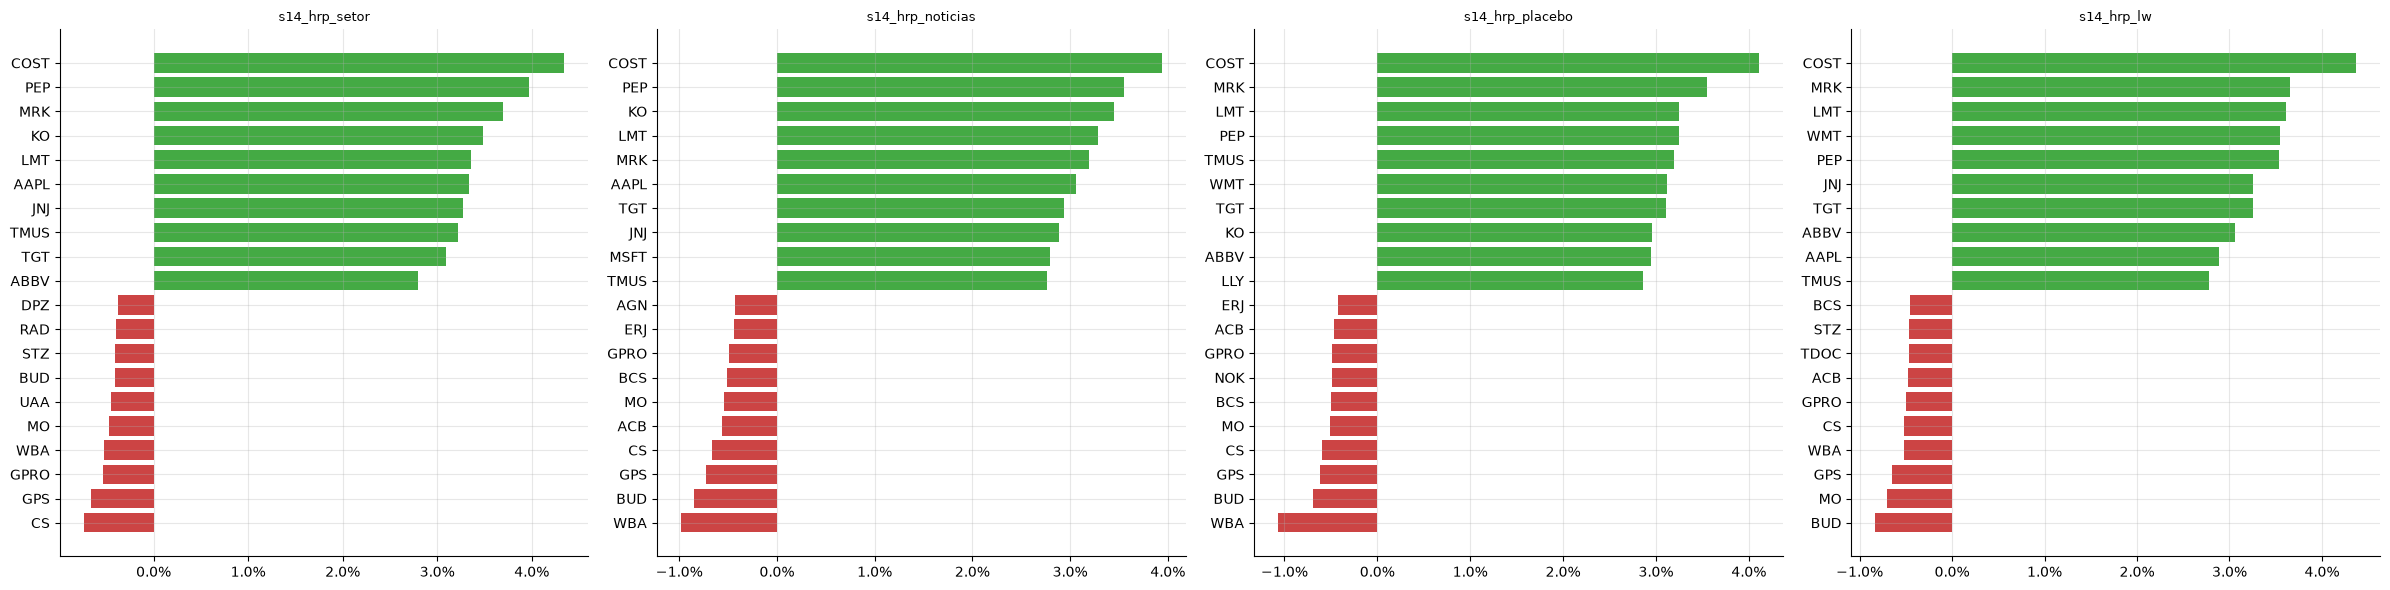

In [16]:
fig, axs = plt.subplots(1, len(runs), figsize=(6 * len(runs), 6), squeeze=False)
for ax, (n, r) in zip(axs[0], runs.items()):
    c = r.positions.groupby("ticker")["contrib"].sum().sort_values()
    sel = pd.concat([c.head(10), c.tail(10)])
    ax.barh(sel.index, sel.values, color=["#c44" if v < 0 else "#4a4" for v in sel.values])
    ax.xaxis.set_major_formatter(pct); ax.set_title(n, fontsize=9)
plt.tight_layout(); plt.show()

## Diagnósticos do modelo

O que o plugin registrou em `ctx.info`: número de condição da correlação estimada (λmax/λmin, López de
Prado), volatilidade ex ante prevista e a volatilidade realizada no período seguinte, intensidade do
shrinkage (δ)...

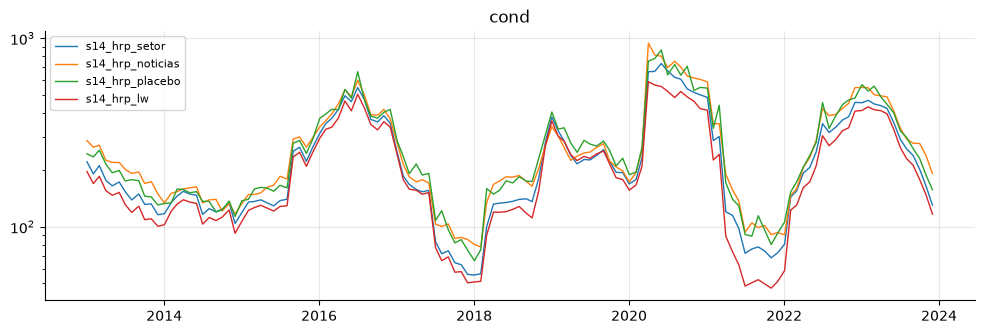

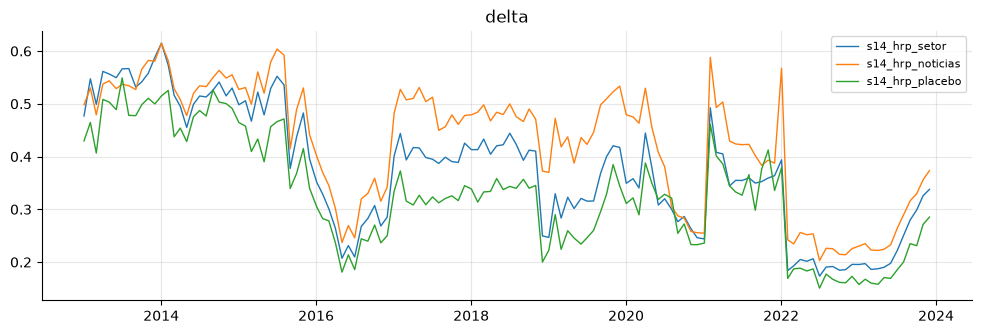

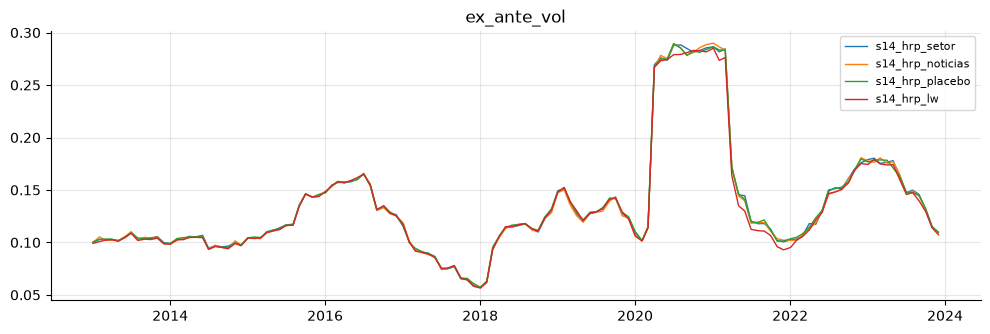

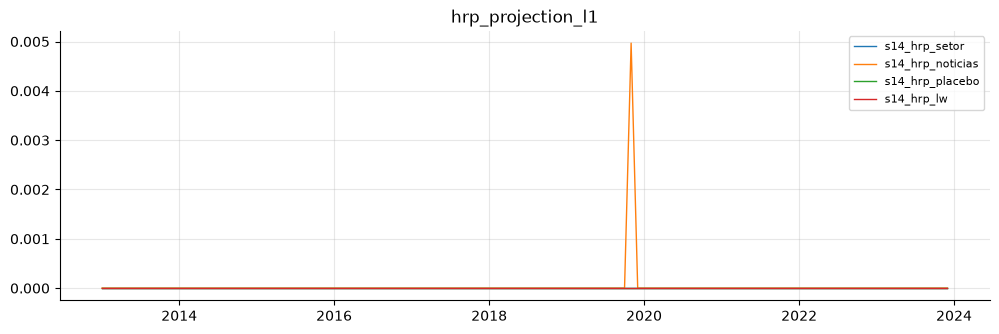

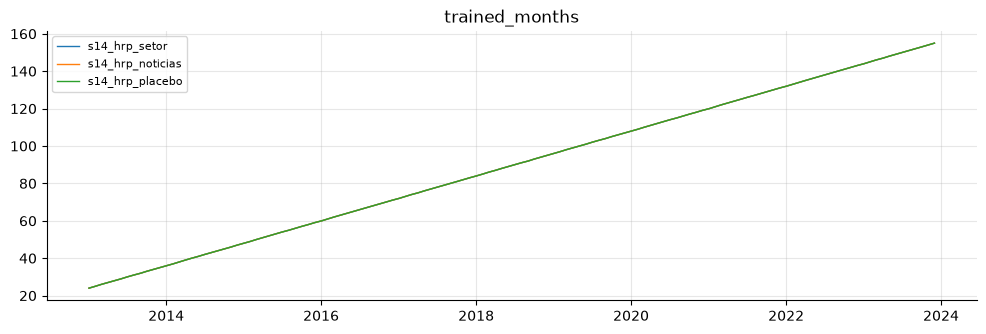

In [17]:
infos = {n: [c for c in r.rebalances.columns if c.startswith("info_")] for n, r in runs.items()}
keys = sorted({c for v in infos.values() for c in v})
if not keys:
    print("nenhum plugin registrou diagnósticos")
for k in keys:
    if k.startswith("info_beta_"):
        continue
    fig, ax = plt.subplots(figsize=(12, 3.5))
    for n, r in runs.items():
        if k in r.rebalances:
            ax.plot(r.rebalances.index, r.rebalances[k], label=n, color=COLORS[n], lw=1)
    ax.set_title(k[5:]); ax.legend(fontsize=8)
    if k == "info_cond":
        ax.set_yscale("log")
    plt.show()

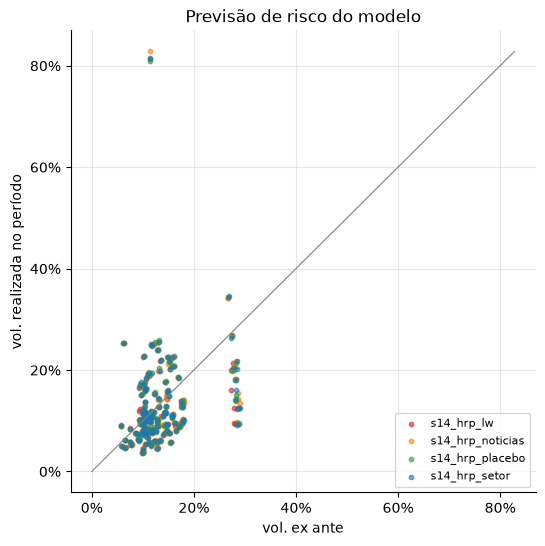

,razão média realizada/ex ante,corr
run,,
s14_hrp_lw,1.0206,0.2244
s14_hrp_noticias,1.0170,0.2182
s14_hrp_placebo,1.0135,0.2142
s14_hrp_setor,1.0129,0.2195


In [18]:
# vol. ex ante (prevista pelo modelo no rebalanceamento) contra a realizada até o próximo
rows = []
for n, r in runs.items():
    if "info_ex_ante_vol" not in r.rebalances:
        continue
    d = r.daily["ret"]
    starts = list(r.rebalances.index) + [d.index[-1] + pd.Timedelta(days=1)]
    for a, b, ex in zip(starts[:-1], starts[1:], r.rebalances["info_ex_ante_vol"]):
        x = d[(d.index >= a) & (d.index < b)]
        if len(x) > 5:
            rows.append({"run": n, "date": a, "ex_ante": ex, "realizada": x.std() * np.sqrt(252)})
if rows:
    V = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(6, 6))
    for n, g in V.groupby("run"):
        ax.scatter(g["ex_ante"], g["realizada"], s=10, alpha=.6, label=n, color=COLORS[n])
    m = V[["ex_ante", "realizada"]].to_numpy().max()
    ax.plot([0, m], [0, m], color="grey", lw=.8)
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel("vol. ex ante"); ax.set_ylabel("vol. realizada no período"); ax.legend(fontsize=8)
    ax.set_title("Previsão de risco do modelo")
    plt.show()
    display(V.groupby("run").apply(lambda g: pd.Series({
        "razão média realizada/ex ante": (g["realizada"] / g["ex_ante"]).mean(),
        "corr": g[["ex_ante", "realizada"]].corr().iloc[0, 1]}), include_groups=False))